## Pochopenie ciela
**Obchodný cieľ:**

Cieľom projektu je znížiť fluktuáciu zamestnancov a súvisiace náklady na nábor, výber a zaškolenie nových pracovníkov. Organizácia chce identifikovať hlavné faktory, ktoré súvisia s odchodom zamestnancov, a včas rozpoznať skupiny pracovníkov so zvýšeným rizikom odchodu. Na základe získaných poznatkov bude možné navrhnúť opatrenia na zvýšenie spokojnosti zamestnancov a zlepšenie ich dlhodobého zotrvania v spoločnosti.

**Cieľ analýzy dát:**

Cieľom analýzy dát je identifikovať vzťahy medzi charakteristikami zamestnancov a ich odchodom zo spoločnosti a vytvoriť modely umožňujúce predikciu fluktuácie zamestnancov.

V rámci projektu budú realizované nasledujúce úlohy:

1. **Klasifikácia:** Vytvorenie a porovnanie klasifikačných modelov na predikciu odchodu zamestnanca na základe jeho pracovných, demografických a osobných charakteristík. Cieľovým atribútom bude `Attrition` (Yes/No).

2. **Zhlukovanie:** Identifikácia skupín zamestnancov s podobnými charakteristikami a analýza miery fluktuácie v jednotlivých zhlukoch.

3. **Asociačná analýza:** Vyhľadávanie zaujímavých vzťahov a kombinácií atribútov, ktoré sa často vyskytujú u zamestnancov, ktorí opustili spoločnosť.

Výsledkom bude porovnanie prediktívnych a opisných modelov, identifikácia najvýznamnejších faktorov súvisiacich s fluktuáciou a formulácia odporúčaní pre personálne riadenie.

## Pochopenie dat

In [1]:
import pandas as pd

df = pd.read_csv("HR-Employee-Attrition.csv")
display(df.head())
display(df.info())
display(df.describe())
print("Dataset shape: ", df.shape)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

None

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


Dataset shape:  (1470, 35)


In [2]:
print(df.isnull().sum())

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [3]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [4]:
print(df.nunique().sort_values())

EmployeeCount                  1
Over18                         1
StandardHours                  1
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age                           43
HourlyRate

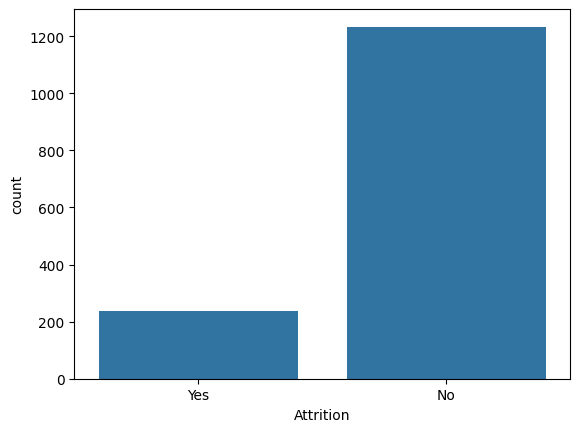

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='Attrition')
plt.show()

In [6]:
print(df['Attrition'].value_counts())

print(
    df['Attrition'].value_counts(normalize=True) * 100
)

Attrition
No     1233
Yes     237
Name: count, dtype: int64
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


In [7]:
from sklearn.model_selection import train_test_split

# Remove attributes that contain no useful information
columns_to_remove = [
    'EmployeeNumber',
    'EmployeeCount',
    'StandardHours',
    'Over18'
]

X = df.drop(columns=['Attrition'] + columns_to_remove)
y = df['Attrition']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nTrain target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Train: (1176, 30)
Test: (294, 30)

Train target distribution:
Attrition
No     0.838435
Yes    0.161565
Name: proportion, dtype: float64

Test target distribution:
Attrition
No     0.840136
Yes    0.159864
Name: proportion, dtype: float64


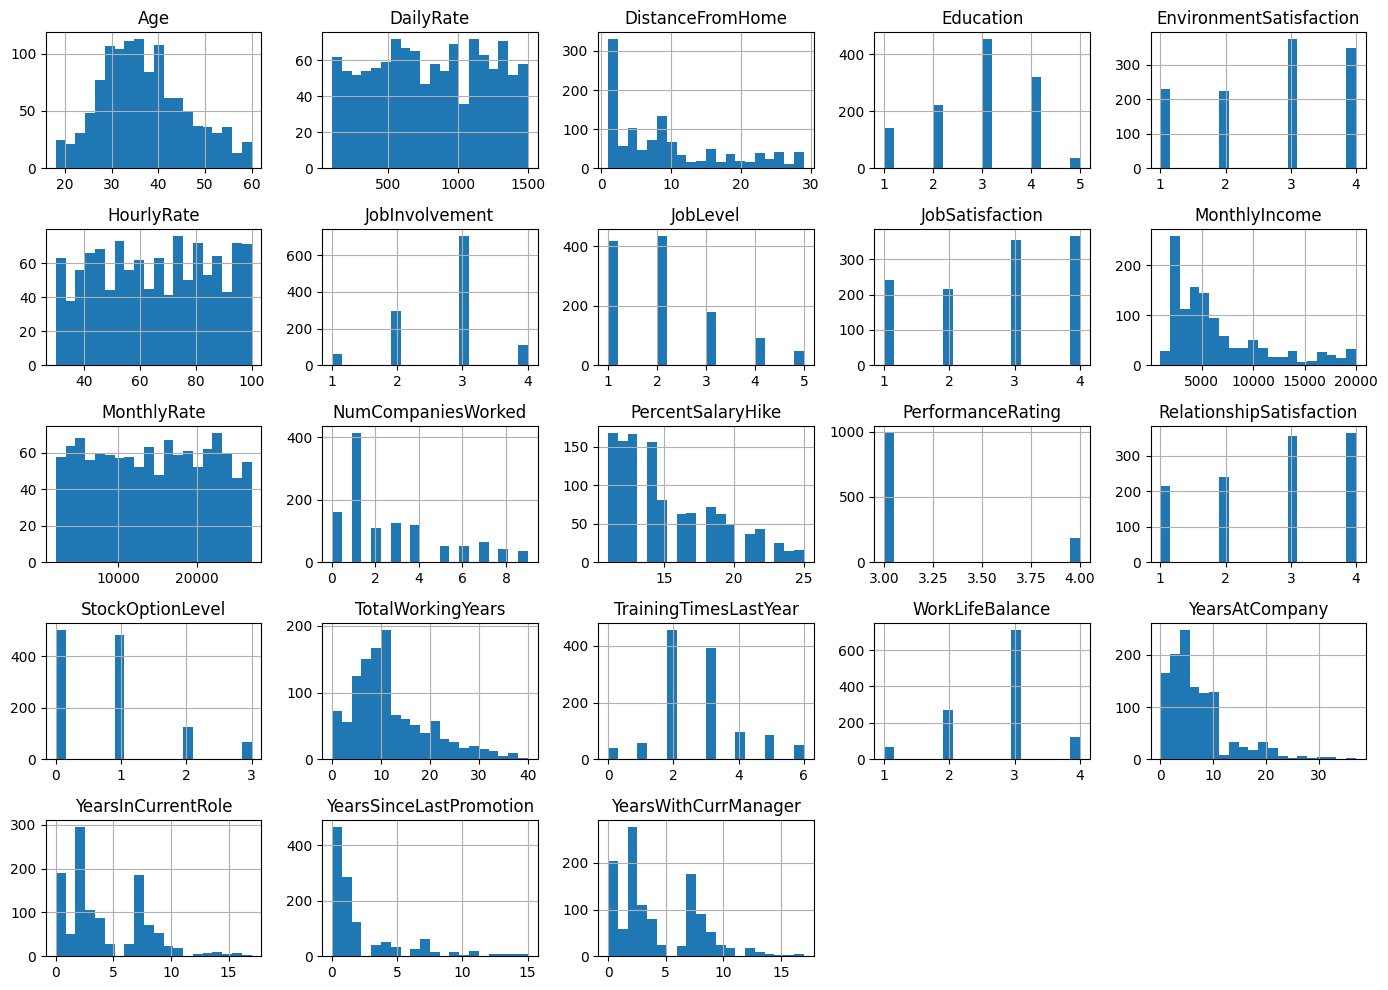

In [8]:
import matplotlib.pyplot as plt
import numpy as np

X_train.hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

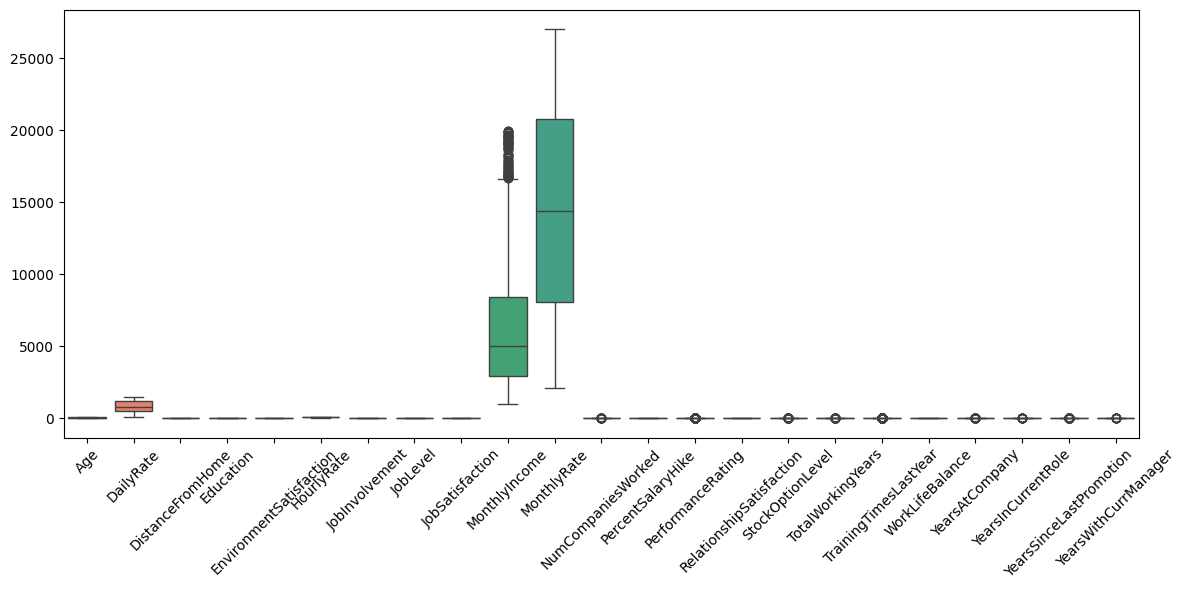

In [9]:
import seaborn as sns

numeric = X_train.select_dtypes(include=np.number)

plt.figure(figsize=(12, 6))
sns.boxplot(data=numeric)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

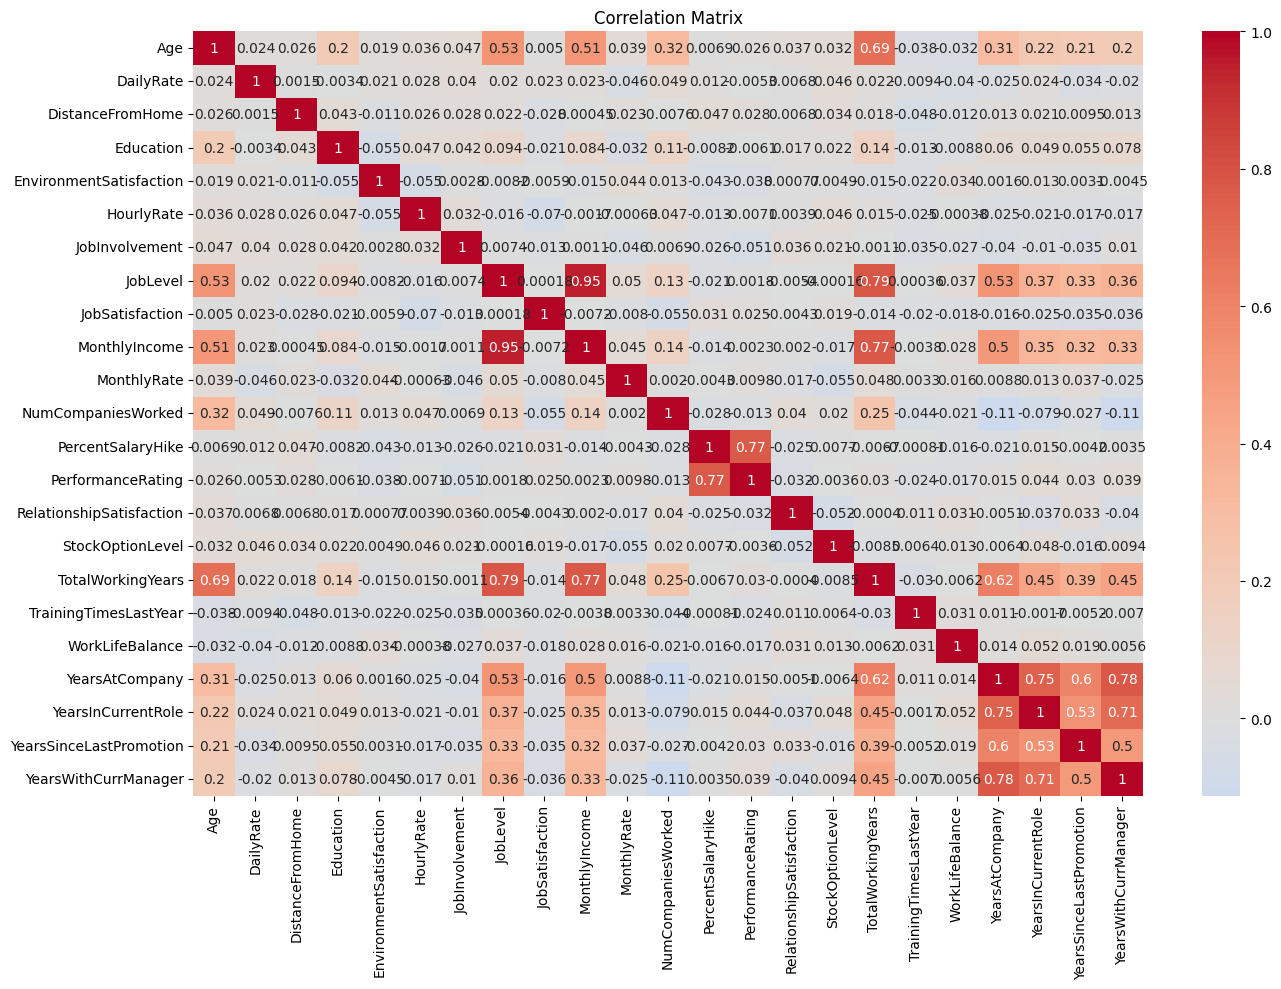

Highly correlated pairs (|r| > 0.85):


,Attribute 1,Attribute 2,Correlation
134,JobLevel,MonthlyIncome,0.947008


In [10]:
corr_data = X_train.select_dtypes(include=np.number)

corr_matrix = corr_data.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    annot=True
)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

# Find highly correlated attributes
threshold = 0.85

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = upper_triangle.stack().reset_index()
high_corr.columns = ['Attribute 1', 'Attribute 2', 'Correlation']

high_corr = high_corr[
    high_corr['Correlation'].abs() > threshold
]

print(f"Highly correlated pairs (|r| > {threshold}):")
display(high_corr)

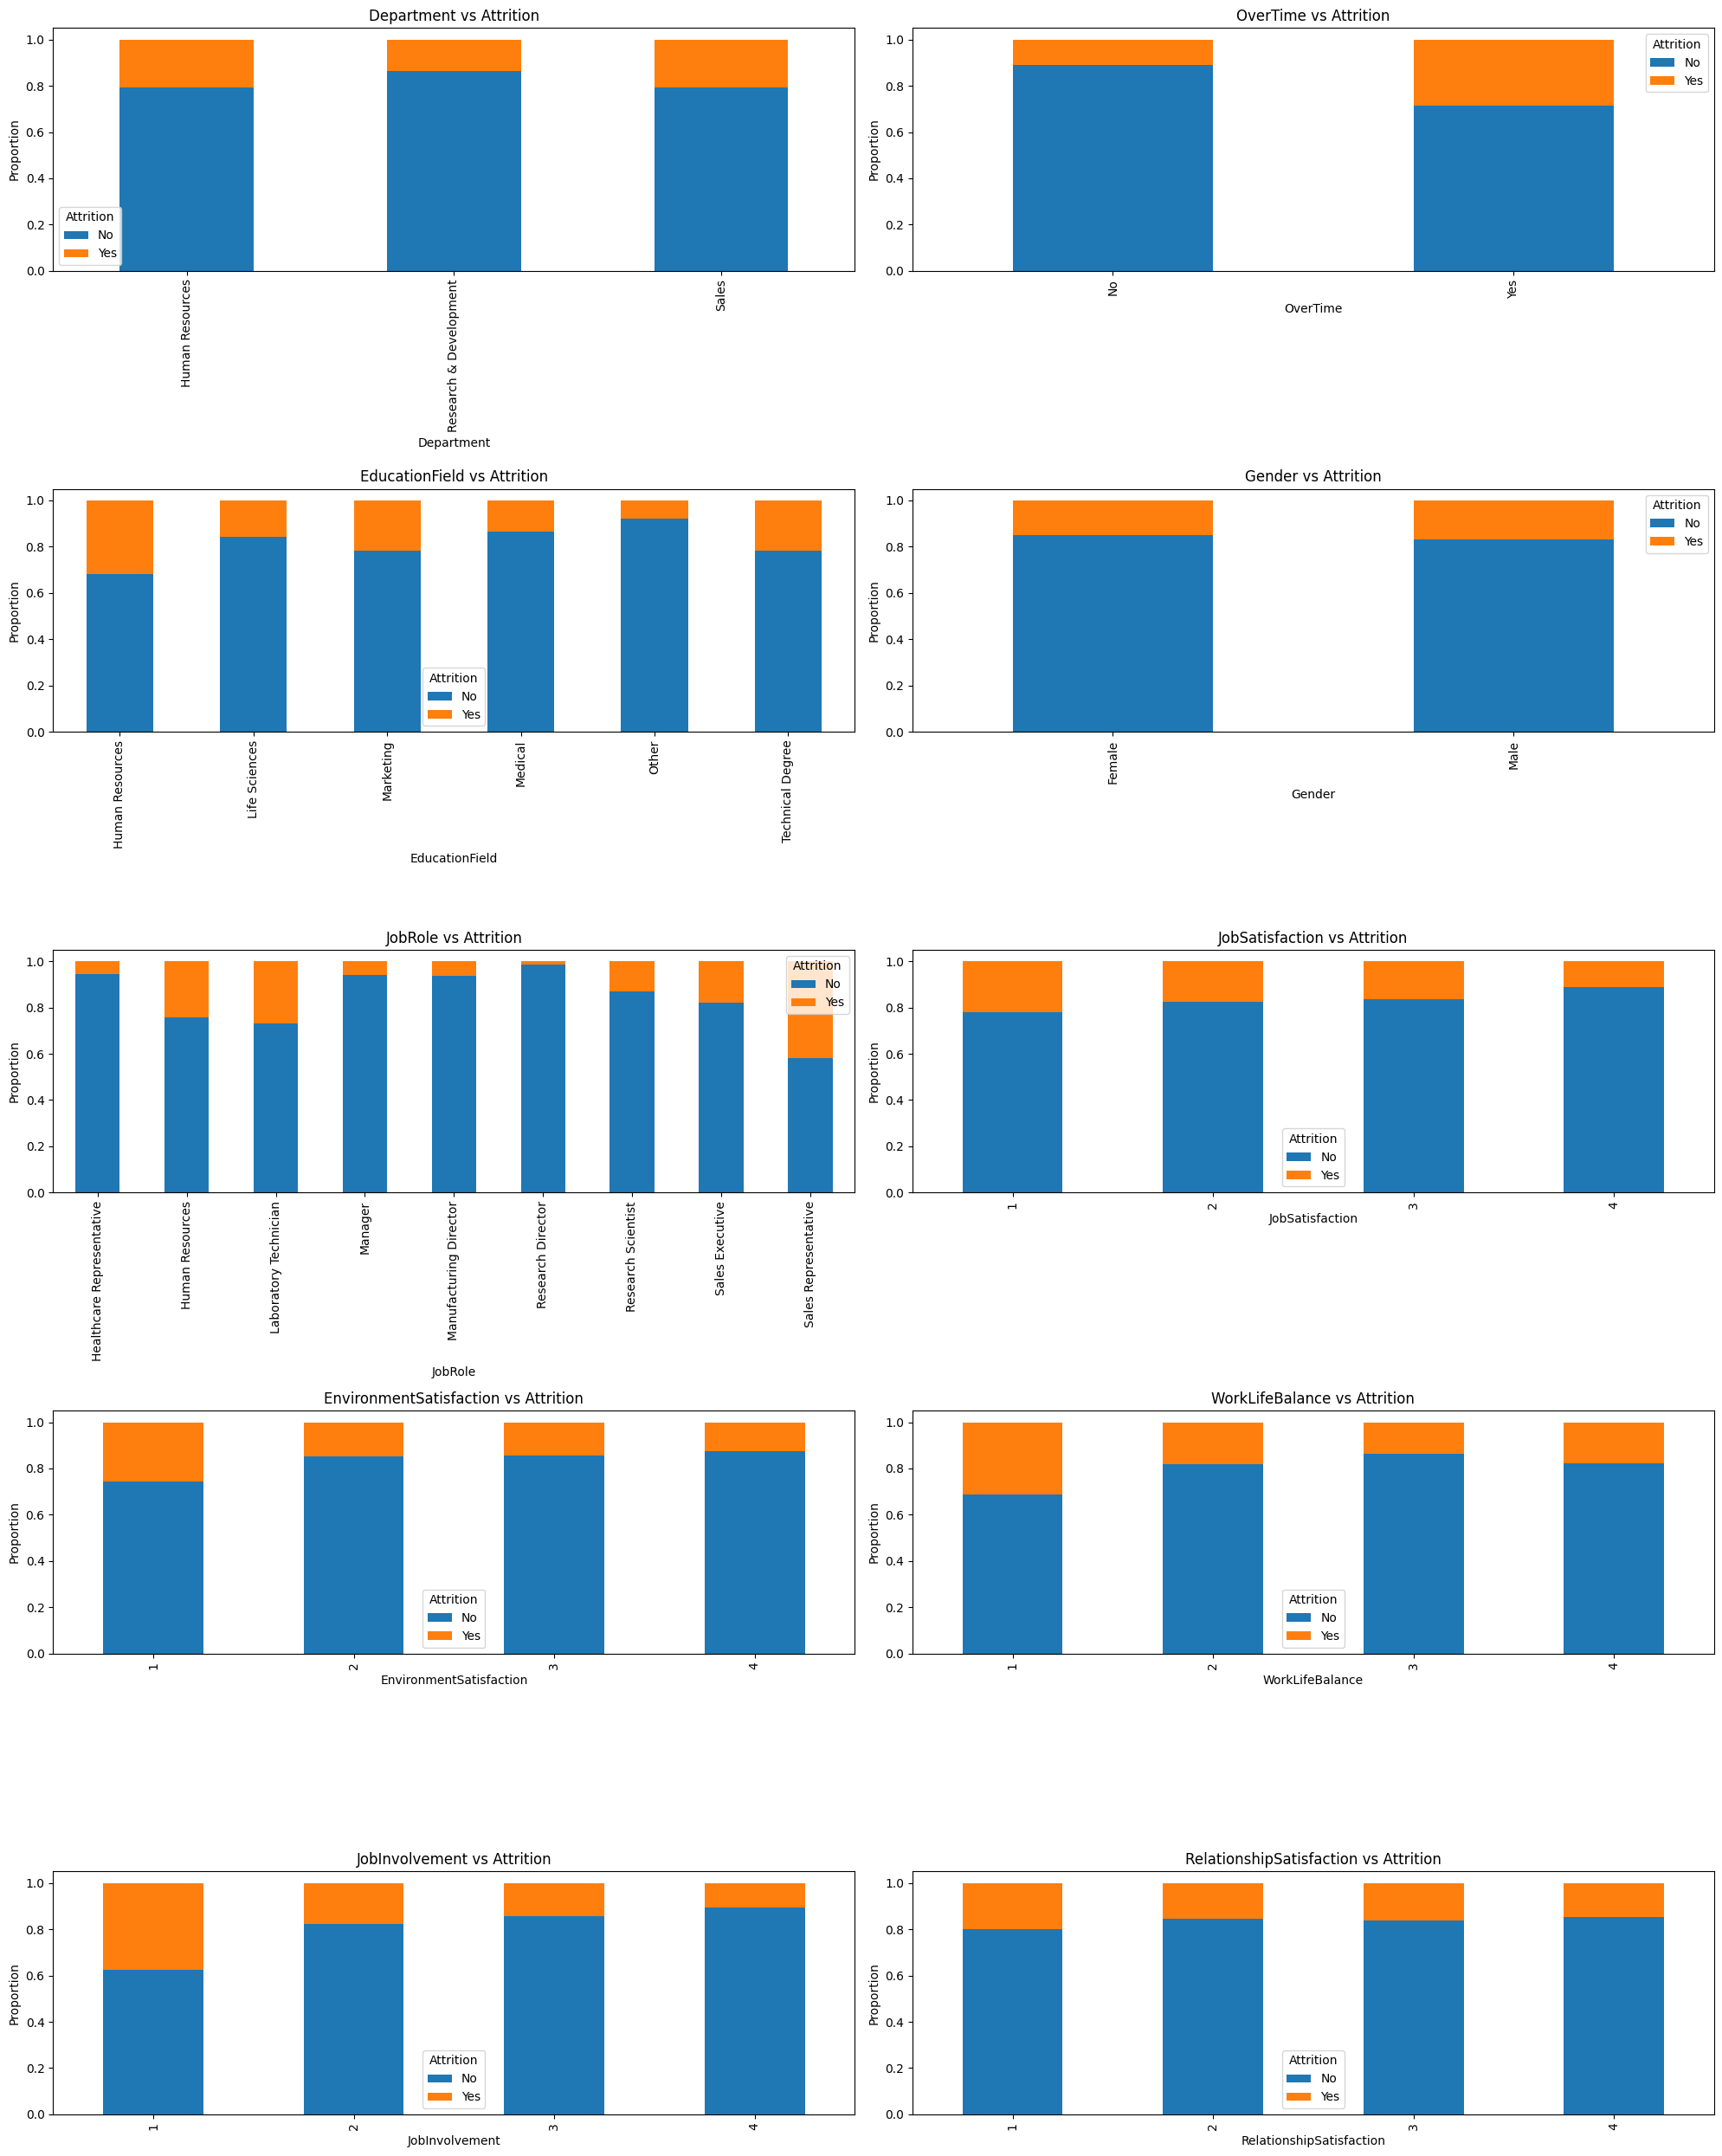

In [11]:
fig, axes = plt.subplots(5, 2, figsize=(20, 25))
axes = axes.flatten()

nom_features = ['Department', 'OverTime', 'EducationField', 
            'Gender', 'JobRole', 'JobSatisfaction', 
            'EnvironmentSatisfaction', 'WorkLifeBalance', 
            'JobInvolvement', 'RelationshipSatisfaction']

for i, feature in enumerate(nom_features):
    pd.crosstab(
        X_train[feature],
        y_train,
        normalize='index'
    ).plot(
        kind='bar',
        stacked=True,
        ax=axes[i]
    )

    axes[i].set_title(f'{feature} vs Attrition')
    axes[i].set_ylabel('Proportion')
    axes[i].set_xlabel(feature)
    axes[i].legend(title='Attrition')

plt.tight_layout()
plt.show()

In [12]:
from scipy.stats import chi2_contingency

for feature in nom_features:
    table = pd.crosstab(X_train[feature], y_train)
    chi2, p, dof, expected = chi2_contingency(table)

    print(f'{feature}: p-value = {p:.5f}, statistically significant association: {p<0.05}')

Department: p-value = 0.00547, statistically significant association: True
OverTime: p-value = 0.00000, statistically significant association: True
EducationField: p-value = 0.01200, statistically significant association: True
Gender: p-value = 0.44181, statistically significant association: False
JobRole: p-value = 0.00000, statistically significant association: True
JobSatisfaction: p-value = 0.00423, statistically significant association: True
EnvironmentSatisfaction: p-value = 0.00017, statistically significant association: True
WorkLifeBalance: p-value = 0.00096, statistically significant association: True
JobInvolvement: p-value = 0.00001, statistically significant association: True
RelationshipSatisfaction: p-value = 0.38184, statistically significant association: False


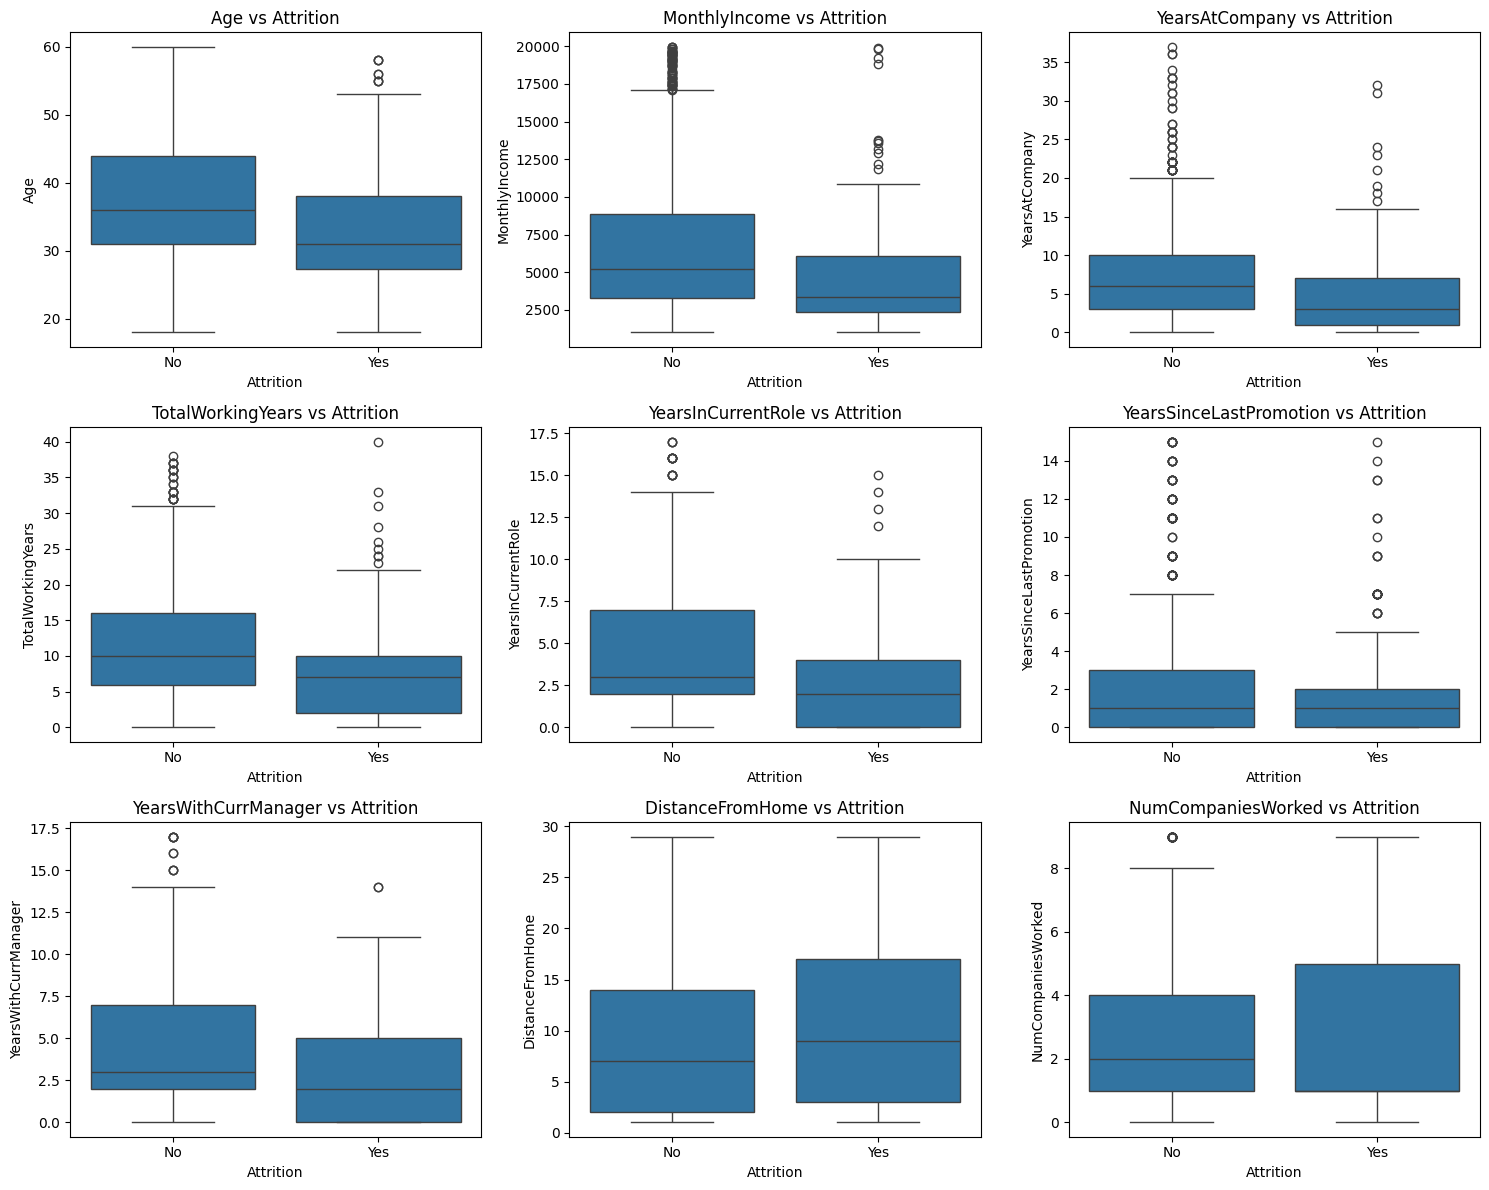

In [13]:
num_features = [
    'Age',
    'MonthlyIncome',
    'YearsAtCompany',
    'TotalWorkingYears',
    'YearsInCurrentRole',
    'YearsSinceLastPromotion',
    'YearsWithCurrManager',
    'DistanceFromHome',
    'NumCompaniesWorked'
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, feature in enumerate(num_features):
    sns.boxplot(
        data=X_train,
        x=y_train,
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f'{feature} vs Attrition')

plt.tight_layout()
plt.show()

In [14]:
from scipy.stats import f_oneway

for feature in num_features:
    yes = X_train[y_train == 'Yes'][feature]
    no = X_train[y_train == 'No'][feature]

    f_stat, p_value = f_oneway(yes, no)

    print(f'{feature}: F = {f_stat:.3f}, p-value = {p_value:.5f}, statistically significant association: {p_value<0.05}')

Age: F = 41.729, p-value = 0.00000, statistically significant association: True
MonthlyIncome: F = 31.018, p-value = 0.00000, statistically significant association: True
YearsAtCompany: F = 28.953, p-value = 0.00000, statistically significant association: True
TotalWorkingYears: F = 42.143, p-value = 0.00000, statistically significant association: True
YearsInCurrentRole: F = 33.693, p-value = 0.00000, statistically significant association: True
YearsSinceLastPromotion: F = 2.169, p-value = 0.14110, statistically significant association: False
YearsWithCurrManager: F = 34.428, p-value = 0.00000, statistically significant association: True
DistanceFromHome: F = 8.901, p-value = 0.00291, statistically significant association: True
NumCompaniesWorked: F = 2.785, p-value = 0.09542, statistically significant association: False


## Priprava dat

In [15]:
colums_with_no_statistically_significant_association = ['Gender', 'RelationshipSatisfaction', 'YearsSinceLastPromotion', 'NumCompaniesWorked']
X_train = X_train.drop(columns=colums_with_no_statistically_significant_association)
X_test = X_test.drop(columns=colums_with_no_statistically_significant_association)

In [16]:
colums_with_high_corr_with_oter_attributes = ['JobLevel']
X_train = X_train.drop(columns=colums_with_high_corr_with_oter_attributes)
X_test = X_test.drop(columns=colums_with_high_corr_with_oter_attributes)

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'PercentSalaryHike', 'PerformanceRating', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsWithCurrManager']
Categorical features: ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus', 'OverTime']


In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    sparse_threshold=0
)

In [19]:
X_train_prepared = preprocessor.fit_transform(X_train)

X_test_prepared = preprocessor.transform(X_test)

In [20]:
feature_names = preprocessor.get_feature_names_out()

X_train_prepared = pd.DataFrame(
    X_train_prepared,
    columns=feature_names,
    index=X_train.index
)

X_test_prepared = pd.DataFrame(
    X_test_prepared,
    columns=feature_names,
    index=X_test.index
)

display(X_train_prepared.head())
print("Prepared train shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)

,num__Age,num__DailyRate,num__DistanceFromHome,num__Education,num__EnvironmentSatisfaction,num__HourlyRate,num__JobInvolvement,num__JobSatisfaction,num__MonthlyIncome,num__MonthlyRate,...,cat__JobRole_Manufacturing Director,cat__JobRole_Research Director,cat__JobRole_Research Scientist,cat__JobRole_Sales Executive,cat__JobRole_Sales Representative,cat__MaritalStatus_Divorced,cat__MaritalStatus_Married,cat__MaritalStatus_Single,cat__OverTime_No,cat__OverTime_Yes
1194,1.090194,1.049455,-0.899915,1.064209,-0.658710,-0.908436,1.795282,-0.647997,2.026752,0.931289,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
128,-1.634828,-0.523449,-0.899915,-1.855332,0.260202,1.694111,0.373564,1.153526,-0.864408,0.682742,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
810,0.981193,-0.992080,-0.777610,-1.855332,-1.577622,-0.662913,0.373564,0.252765,2.347706,0.167705,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
478,-1.307825,-0.453653,0.445433,-1.855332,-0.658710,-1.252169,0.373564,0.252765,-0.956202,1.667056,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
491,0.654191,0.491086,-0.043784,2.037390,1.179114,0.319180,0.373564,0.252765,-0.185956,0.728362,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


Prepared train shape: (1176, 45)
Prepared test shape: (294, 45)


In [21]:
display(
    X_train_prepared[
        [f'num__{col}' for col in numeric_features]
    ].describe().round(2)
)

,num__Age,num__DailyRate,num__DistanceFromHome,num__Education,num__EnvironmentSatisfaction,num__HourlyRate,num__JobInvolvement,num__JobSatisfaction,num__MonthlyIncome,num__MonthlyRate,num__PercentSalaryHike,num__PerformanceRating,num__StockOptionLevel,num__TotalWorkingYears,num__TrainingTimesLastYear,num__WorkLifeBalance,num__YearsAtCompany,num__YearsInCurrentRole,num__YearsWithCurrManager
count,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00
mean,-0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.07,-1.75,-1.02,-1.86,-1.58,-1.74,-2.47,-1.55,-1.19,-1.71,-1.15,-0.43,-0.94,-1.46,-2.20,-2.45,-1.16,-1.19,-1.18
25%,-0.76,-0.84,-0.90,-0.88,-0.66,-0.86,-1.05,-0.65,-0.77,-0.88,-0.88,-0.43,-0.94,-0.69,-0.61,-1.06,-0.67,-0.63,-0.62
50%,-0.11,-0.01,-0.29,0.09,0.26,0.02,0.37,0.25,-0.33,-0.00,-0.34,-0.43,0.25,-0.18,0.19,0.34,-0.34,-0.35,-0.34
75%,0.65,0.88,0.57,1.06,1.18,0.86,0.37,1.15,0.40,0.89,0.75,-0.43,0.25,0.47,0.19,0.34,0.48,0.78,0.79
max,2.51,1.73,2.40,2.04,1.18,1.69,1.80,1.15,2.89,1.75,2.65,2.31,2.61,3.67,2.58,1.73,4.92,3.58,3.59


## Modelovanie

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

In [25]:
for name, model in models.items():
    model.fit(X_train_prepared, y_train)
    print(f'{name}: training completed')

Logistic Regression: training completed
Decision Tree: training completed
Random Forest: training completed


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

results = []
for name, model in models.items():
    y_pred = model.predict(X_test_prepared)
    yes_index = list(model.classes_).index('Yes')
    y_proba = model.predict_proba(X_test_prepared)[:, yes_index]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label='Yes', zero_division=0)
    recall = recall_score(y_test, y_pred, pos_label='Yes', zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label='Yes', zero_division=0)
    roc_auc = roc_auc_score(
        (y_test == 'Yes').astype(int),
        y_proba
    )
    confusion_mat = confusion_matrix(y_test, y_pred)

    results.append(
        {
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "roc_auc": roc_auc,
            "confuscion_matrix": confusion_mat
        }
    )

results = pd.DataFrame(results)
display(results)    

,accuracy,precision,recall,f1,roc_auc,confuscion_matrix
0,0.758503,0.353659,0.617021,0.449612,0.780084,"[[194, 53], [18, 29]]"
1,0.795918,0.381818,0.446809,0.411765,0.654578,"[[213, 34], [26, 21]]"
2,0.840136,0.500000,0.106383,0.175439,0.797269,"[[242, 5], [42, 5]]"
